# Results notebook — The City's Heartbeat

**Contents**
1. **Data cleaning and first look at the data**
   - Step 0: inventory of the raw files, trips per month
   - Steps 1–3: common format and dates
   - First look at the data: size, missing values, trips per day
   - Steps 4–7: durations, station positions, cleaning rules, full run
   - Summary of the clean data
2. **Descriptive statistics: is 2022–2025 a stable period to define "normal"?** Daily rhythm, rider mix, total volume, network size, e-bikes : JEANNE
3. **Choice of the grid: day vs hour, zones, hybrid grid, stations** : JEANNE
4. **External data** (weather, holidays, events): to be DONE
- correlation !!
5. **Model of a "normal" day** (equations): LAURE

#### Imports

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data cleaning

### Step 0 — Inventory of the raw files

➕ 96 zip files, 116 CSVs: 108 trip files + 8 station files. From their column names, every CSV falls into one of 6 format families; none is unknown.

In [2]:
from src.data.inventory import build_inventory

inventory = build_inventory("data/raw")
inventory["family"].value_counts()

family
new_2020_2026     79
old_2014_2016     16
old_2017_2019     10
stations           8
old_long_names     2
old_2013           1
Name: count, dtype: int64

#### Trips per month in every raw file

➕ Goal: count trips per month in each CSV, from the dates inside the files (reads only the start-time column of 58 million trips: slow).
- we use the **dates inside the files** because some zip files are wrongly named (the zip `202601` contains a CSV named `202501`).

In [3]:
import matplotlib.pyplot as plt
from src.data.inventory import trips_per_month

monthly = trips_per_month(inventory)     # trips per month in every CSV (reads the raw zip files)
print(len(monthly), "rows (file × month)")
monthly.head()

187 rows (file × month)


,csv,month,n_trips
0,202004-divvy-tripdata.csv,2020-04,84776
1,202005-divvy-tripdata.csv,2020-05,200274
2,202006-divvy-tripdata.csv,2020-06,343005
3,202007-divvy-tripdata.csv,2020-07,551480
4,202008-divvy-tripdata.csv,2020-08,622361


#### Missing months, and months found in several files

➕ No month is missing (June 2013 → September 2026). But from May 2024, almost every month appears in two files
- Careful: this test counts a month as "in two files" as soon as **one single trip** of that month is in another file. The next cell measures how many trips that really is. 

In [4]:
import pandas as pd

# 1. Missing months
all_months = pd.period_range("2013-06", "2026-09", freq="M")
missing = all_months.difference(monthly["month"].unique())
print("Missing months:", list(missing))

# 2. Months found in more than one file
files_per_month = monthly.groupby("month")["csv"].nunique()
print("Months in several files:", list(files_per_month[files_per_month > 1].index))

Missing months: []
Months in several files: [Period('2024-05', 'M'), Period('2024-06', 'M'), Period('2024-07', 'M'), Period('2024-08', 'M'), Period('2024-09', 'M'), Period('2024-10', 'M'), Period('2024-11', 'M'), Period('2024-12', 'M'), Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M'), Period('2025-04', 'M'), Period('2025-05', 'M'), Period('2025-06', 'M'), Period('2025-07', 'M'), Period('2025-08', 'M'), Period('2025-09', 'M'), Period('2025-10', 'M'), Period('2025-11', 'M'), Period('2025-12', 'M'), Period('2026-01', 'M'), Period('2026-02', 'M'), Period('2026-04', 'M'), Period('2026-05', 'M'), Period('2026-06', 'M'), Period('2026-07', 'M'), Period('2026-08', 'M')]


#### Months really covered by two files

➕ For each month, we compute the share of its trips found in each file. If a month were really split between two files, one file would hold between 1% and 99% of it: this never happens. So the second file only holds a handful of trips, less than 1% of the month.

➕ These few trips are "stray trips": trips that start just before midnight at the end of a month and end after midnight (e.g. a trip from 31 May 23:50 to 1 June 00:10 is in the **June** file). From June 2024, Divvy seems to put each trip in the file of the month it **ends** in, instead of the month it starts in: Divvy does not document it, but the check below confirms it on three files (100% of stray trips end in the file's month), and it also explains the few duplicated trips at the change (Step 7). No problem for the analysis: each trip is counted on its real start date, whatever file it is in.

In [5]:
share = monthly.groupby(["month", "csv"])["n_trips"].sum()
share = share / share.groupby("month").transform("sum")
overlaps = share[(share > 0.01) & (share < 0.99)]
print("Months really covered by two files:\n", overlaps)

Months really covered by two files:
 Series([], Name: n_trips, dtype: float64)


#### Check: do the stray trips end in the next month?

➕ Goal: check the explanation of the stray trips in three files after June 2024. Result: confirmed. In July 2024, October 2024 and March 2025, 100% of the trips that started in the previous month end in the file's month, and they start just before midnight (median 23:36 to 23:53). They are very few: 237, 35 and 36 trips, i.e. 0.006% to 0.03% of each file.

In [6]:
for name in ["202407", "202410", "202503"]:
    f = glob.glob(f"data/interim/{name}-divvy*__*.parquet")[0]
    d = pd.read_parquet(f, columns=["started_at", "ended_at"])
    month_start = pd.Timestamp(f"{name[:4]}-{name[4:]}-01")
    stray = d[d["started_at"] < month_start]
    print(f"{name}: {len(stray)} stray trips out of {len(d):,} "
          f"| ending in the file's month: {(stray['ended_at'] >= month_start).mean() * 100:.0f}% "
          f"| median start: {stray['started_at'].median()}")

202407: 237 stray trips out of 748,962 | ending in the file's month: 100% | median start: 2024-06-30 23:36:13.907000
202410: 35 stray trips out of 616,281 | ending in the file's month: 100% | median start: 2024-09-30 23:46:21.771000
202503: 36 stray trips out of 298,155 | ending in the file's month: 100% | median start: 2025-02-28 23:53:26.826500


#### 📊 Trips per month, June 2013 – September 2026

➕ Every month is present. Strong seasonality (summer peaks, winter lows); summer peaks grow from ~200,000 (2013) to ~590,000 (2019) with the network, then a plateau around 800,000 from 2021. The COVID drop is hidden by seasonality → next plot.

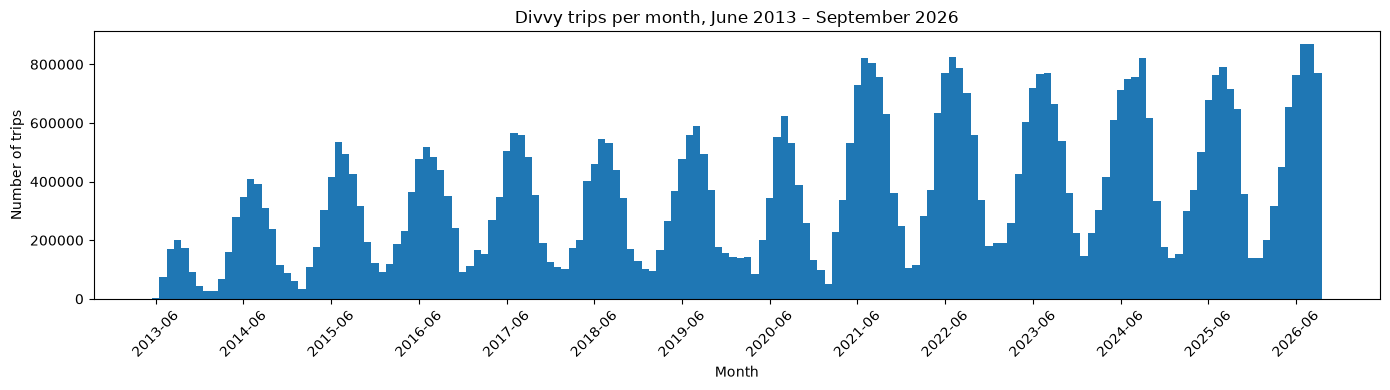

In [7]:
per_month = monthly.groupby("month")["n_trips"].sum()
per_month.index = per_month.index.astype(str)   # ← the fix

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(per_month)), per_month.values, width=1)
ax.set_title("Divvy trips per month, June 2013 – September 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Number of trips")
ax.set_xticks(range(0, len(per_month), 12))
ax.set_xticklabels(per_month.index[::12], rotation=45)
plt.tight_layout()
plt.show()

#### 📊 Trips per month: 2020 vs other years (COVID effect)

➕ 2020: far below the other years in April–May (lockdown), back to normal in July, above 2019 in August–November (rebound). 2021: above the other years from spring, probably because the network changed (more stations, e-bikes): checked in Part 2. February 2021 is unusually low (cold wave?): a test case for the model.

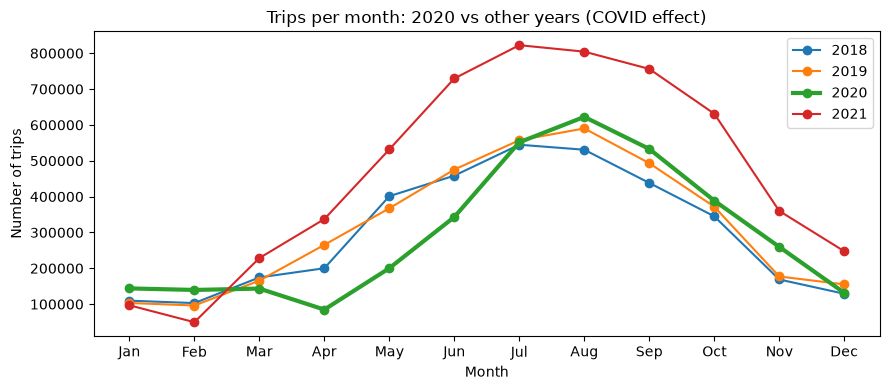

In [8]:
df = monthly.groupby("month")["n_trips"].sum().reset_index()
df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month

fig, ax = plt.subplots(figsize=(9, 4))
for year in [2018, 2019, 2020, 2021]:
    d = df[df["year"] == year]
    ax.plot(d["month_num"], d["n_trips"], marker="o", label=str(year),
            linewidth=3 if year == 2020 else 1.5)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Trips per month: 2020 vs other years (COVID effect)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of trips")
ax.legend()
plt.tight_layout()
plt.show()

### Steps 1–2 — Common format and renaming

➕ Every file is converted to the same 14 columns (+ `source_zip`), with one renaming dictionary per family. Everything is read as text and converted in the next steps; columns a family does not have (GPS before 2020, duration after 2020) are created empty.

#### Test: one file per family

➕ Result: all 5 trip families return exactly the same columns in the same order (`True`).

In [9]:
from src.data.harmonize import load_harmonized

# Take one trip file from each family
samples = inventory[inventory["family"] != "stations"].groupby("family").head(1)

for _, row in samples.iterrows():
    df = load_harmonized(row["zip"], row["csv"], row["family"])
    print(f"=== {row['family']}  ({row['csv']}, {len(df):,} rows)")
    print(list(df.columns) == list(load_harmonized.__globals__["COMMON_COLUMNS"]) + ["source_zip"])
    display(df.head(2))

=== new_2020_2026  (202004-divvy-tripdata.csv, 84,776 rows)
True


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
0,A847FADBBC638E45,2020-04-26 17:45:14,2020-04-26 18:12:03,<NA>,86,Eckhart Park,152,Lincoln Ave & Diversey Pkwy,41.8964,-87.661,41.9322,-87.6586,member,docked_bike,202004-divvy-tripdata.zip
1,5405B80E996FF60D,2020-04-17 17:08:54,2020-04-17 17:17:03,<NA>,503,Drake Ave & Fullerton Ave,499,Kosciuszko Park,41.9244,-87.7154,41.9306,-87.7238,member,docked_bike,202004-divvy-tripdata.zip


=== old_2013  (Divvy_Stations_Trips_2013/Divvy_Trips_2013.csv, 759,788 rows)
True


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
0,4118,2013-06-27 12:11,2013-06-27 12:16,316,85,Michigan Ave & Oak St,28,Larrabee St & Menomonee St,<NA>,<NA>,<NA>,<NA>,Customer,<NA>,Divvy_Stations_Trips_2013.zip
1,4275,2013-06-27 14:44,2013-06-27 14:45,64,32,Racine Ave & Congress Pkwy,32,Racine Ave & Congress Pkwy,<NA>,<NA>,<NA>,<NA>,Customer,<NA>,Divvy_Stations_Trips_2013.zip


=== old_2014_2016  (Divvy_Trips_2014_Q1Q2.csv, 905,699 rows)
True


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
0,2355134,6/30/2014 23:57,7/1/2014 0:07,604,131,Lincoln Ave & Belmont Ave,303,Broadway & Cornelia Ave,<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Stations_Trips_2014_Q1Q2.zip
1,2355133,6/30/2014 23:56,7/1/2014 0:00,263,282,Halsted St & Maxwell St,22,May St & Taylor St,<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Stations_Trips_2014_Q1Q2.zip


=== old_2017_2019  (Divvy_Trips_2017_Q1.csv, 431,691 rows)
True


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
0,13518905,3/31/2017 23:59:07,4/1/2017 00:13:24,857,66,Clinton St & Lake St,171,May St & Cullerton St,<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Trips_2017_Q1Q2.zip
1,13518904,3/31/2017 23:56:25,4/1/2017 00:00:21,236,199,Wabash Ave & Grand Ave,26,McClurg Ct & Illinois St,<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Trips_2017_Q1Q2.zip


=== old_long_names  (Divvy_Trips_2018_Q1.csv, 387,145 rows)
True


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
0,17536702,2018-01-01 00:12:00,2018-01-01 00:17:23,323.0,69,Damen Ave & Pierce Ave,159,Claremont Ave & Hirsch St,<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Trips_2018_Q1.zip
1,17536703,2018-01-01 00:41:35,2018-01-01 00:47:52,377.0,253,Winthrop Ave & Lawrence Ave,325,Clark St & Winnemac Ave (Temp),<NA>,<NA>,<NA>,<NA>,Subscriber,<NA>,Divvy_Trips_2018_Q1.zip


### Step 3 — Dates
#### Test: date parsing, one file per family

➕ The date format of each file is detected from its first value and given explicitly to pandas (4 formats). Result: 0 failed dates, and dates within each file's period.

In [10]:
from src.data.harmonize import load_harmonized
from src.data.convert import parse_dates

samples = inventory[inventory["family"] != "stations"].groupby("family").head(1)

for _, row in samples.iterrows():
    df = load_harmonized(row["zip"], row["csv"], row["family"])
    raw_example = df["started_at"].iloc[0]
    df, n_failed = parse_dates(df)
    print(f"{row['family']:15} | {raw_example!r:25} -> {df['started_at'].iloc[0]} "
          f"| failed: {n_failed} | from {df['started_at'].min()} to {df['started_at'].max()}")

new_2020_2026   | '2020-04-26 17:45:14'     -> 2020-04-26 17:45:14 | failed: 0 | from 2020-04-01 00:00:30 to 2020-04-30 23:57:20
old_2013        | '2013-06-27 12:11'        -> 2013-06-27 12:11:00 | failed: 0 | from 2013-06-27 01:06:00 to 2013-12-31 23:46:00
old_2014_2016   | '6/30/2014 23:57'         -> 2014-06-30 23:57:00 | failed: 0 | from 2014-01-01 00:17:00 to 2014-06-30 23:57:00
old_2017_2019   | '3/31/2017 23:59:07'      -> 2017-03-31 23:59:07 | failed: 0 | from 2017-01-01 00:00:36 to 2017-03-31 23:59:07
old_long_names  | '2018-01-01 00:12:00'     -> 2018-01-01 00:12:00 | failed: 0 | from 2018-01-01 00:12:00 to 2018-03-31 23:53:38


#### Full run of steps 1–3: all 108 files → `data/interim/`

➕ Result: 58,209,830 trips, 0 failed dates; log saved in `data/interim/log_steps_1_3.csv`. Slow: no need to rerun.

In [11]:
from src.data.pipeline import run_steps_1_to_3

log_1_3 = run_steps_1_to_3(inventory)
log_1_3.to_csv("data/interim/log_steps_1_3.csv", index=False)

print("Total rows:", log_1_3["n_rows"].sum())
print("Total failed dates:", log_1_3["failed_dates"].sum())
log_1_3[log_1_3["failed_dates"] > 0]

1/108 202004-divvy-tripdata.csv: 84,776 rows, 0 failed
2/108 202005-divvy-tripdata.csv: 200,274 rows, 0 failed
3/108 202006-divvy-tripdata.csv: 343,005 rows, 0 failed
4/108 202007-divvy-tripdata.csv: 551,480 rows, 0 failed
5/108 202008-divvy-tripdata.csv: 622,361 rows, 0 failed
6/108 202009-divvy-tripdata.csv: 532,958 rows, 0 failed
7/108 202010-divvy-tripdata.csv: 388,653 rows, 0 failed
8/108 202011-divvy-tripdata.csv: 259,716 rows, 0 failed
9/108 202012-divvy-tripdata.csv: 131,573 rows, 0 failed
10/108 202101-divvy-tripdata.csv: 96,834 rows, 0 failed
11/108 202102-divvy-tripdata.csv: 49,622 rows, 0 failed
12/108 202103-divvy-tripdata.csv: 228,496 rows, 0 failed
13/108 202104-divvy-tripdata.csv: 337,230 rows, 0 failed
14/108 202105-divvy-tripdata.csv: 531,633 rows, 0 failed
15/108 202106-divvy-tripdata.csv: 729,595 rows, 0 failed
16/108 202107-divvy-tripdata.csv: 822,410 rows, 0 failed
17/108 202108-divvy-tripdata.csv: 804,352 rows, 0 failed
18/108 202109-divvy-tripdata.csv: 756,147 r

,zip,csv,family,n_rows,failed_dates,first,last,interim_file


#### Period covered by each file

➕ Check of the dates in all 108 files: each file's first and last month match the period in its name, so dates are read correctly (a swapped month and day would put trips outside the period). Two mismatches, both explained: files from June 2024 start just before midnight on the last day of the previous month (trips from the previous month), and the zip `202601` has a wrong CSV name (`202501`).

In [12]:
import pandas as pd
pd.set_option("display.max_rows", 120)
log_1_3["first_month"] = log_1_3["first"].dt.strftime("%Y-%m")
log_1_3["last_month"] = log_1_3["last"].dt.strftime("%Y-%m")
log_1_3[["zip", "csv", "n_rows", "first_month", "last_month"]]

,zip,csv,n_rows,first_month,last_month
0,202004-divvy-tripdata.zip,202004-divvy-tripdata.csv,84776,2020-04,2020-04
1,202005-divvy-tripdata.zip,202005-divvy-tripdata.csv,200274,2020-05,2020-05
2,202006-divvy-tripdata.zip,202006-divvy-tripdata.csv,343005,2020-06,2020-06
3,202007-divvy-tripdata.zip,202007-divvy-tripdata.csv,551480,2020-07,2020-07
4,202008-divvy-tripdata.zip,202008-divvy-tripdata.csv,622361,2020-08,2020-08
5,202009-divvy-tripdata.zip,202009-divvy-tripdata.csv,532958,2020-09,2020-09
6,202010-divvy-tripdata.zip,202010-divvy-tripdata.csv,388653,2020-10,2020-10
7,202011-divvy-tripdata.zip,202011-divvy-tripdata.csv,259716,2020-11,2020-11
8,202012-divvy-tripdata.zip,202012-divvy-tripdata.csv,131573,2020-12,2020-12
9,202101-divvy-tripdata.zip,202101-divvy-tripdata.csv,96834,2021-01,2021-01


#### 📊 Share of trips by hour of the day: old vs new format

➕ The file format changed in January 2020 (dates written differently). To check that hours are read correctly in both formats, we compare one summer of each (2019 old, 2023 new): same shape, same peaks (8:00, 17:00), so no shift. The peaks are lower in 2023 (less commuting after COVID ???).

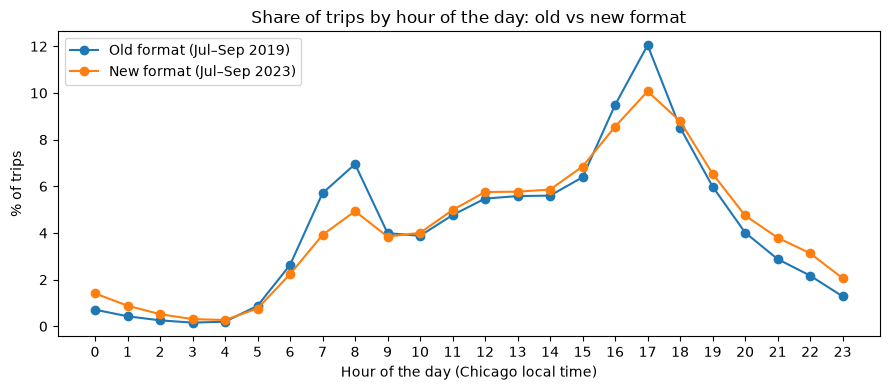

In [13]:
import glob
import matplotlib.pyplot as plt

old = pd.concat(pd.read_parquet(f, columns=["started_at"])
                for f in glob.glob("data/interim/Divvy_Trips_2019_Q3*.parquet"))
new = pd.concat(pd.read_parquet(f, columns=["started_at"])
                for f in glob.glob("data/interim/20230[789]-divvy*.parquet"))

fig, ax = plt.subplots(figsize=(9, 4))
for df, label in [(old, "Old format (Jul–Sep 2019)"), (new, "New format (Jul–Sep 2023)")]:
    share = df["started_at"].dt.hour.value_counts(normalize=True).sort_index()
    ax.plot(share.index, share.values * 100, marker="o", label=label)
ax.set_xticks(range(0, 24))
ax.set_title("Share of trips by hour of the day: old vs new format")
ax.set_xlabel("Hour of the day (Chicago local time)")
ax.set_ylabel("% of trips")
ax.legend()
plt.tight_layout()
plt.show()

### First look at the data — (common format, before cleaning)

#### Size of the data

➕ 58,209,830 trips in 108 files: 1.9 GB of zip files. Files are processed one by one (never all 58 million trips in memory at once) and saved as parquet, which lets us read only the columns we need and keeps dates as dates.

In [19]:
import os

def folder_size_gb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e9

print(f"Raw zip files: {folder_size_gb('data/raw'):.1f} GB | interim parquet: {folder_size_gb('data/interim'):.1f} GB")
print(f"Trips: {log_1_3['n_rows'].sum():,} in {len(log_1_3)} files")

Raw zip files: 1.9 GB | interim parquet: 2.2 GB
Trips: 58,209,830 in 108 files


#### Missing values per column, by format (% of trips)

➕ Expected gaps: before 2020 no GPS position and no bike type, from 2020 no duration (fixed in Steps 4–5). New finding: from 2020, ~16% of trips have no station (e-bikes left outside a station), but all of them have a start position. Before 2020, every trip has a station, so its position can be added from the station files (Step 5).

In [20]:
rows = []
for r in log_1_3.itertuples():
    d = pd.read_parquet(f"data/interim/{r.interim_file}")
    rows.append(d.isna().sum().rename(r.family).to_frame().T.assign(n_rows=len(d)))
missing_by_family = pd.concat(rows).groupby(level=0).sum()
pct_missing = (100 * missing_by_family.drop(columns="n_rows")
               .div(missing_by_family["n_rows"], axis=0)).round(1)
pct_missing

,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip
new_2020_2026,0.0,0.0,0.0,100.0,15.7,15.7,16.5,16.5,0.0,0.0,0.1,0.1,0.0,0.0,0.0
old_2013,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0
old_2014_2016,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0
old_2017_2019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0
old_long_names,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0


#### Trips per day, by year

➕ Order of magnitude of a "normal" day: a median summer day has ~17,000–18,000 trips in 2017–2020 and ~24,000–26,000 in 2021–2025 (jump in 2021). 2013 and 2026 are incomplete years so be careful.

In [21]:
day_counts = []
for r in log_1_3.itertuples():
    s = pd.read_parquet(f"data/interim/{r.interim_file}", columns=["started_at"])["started_at"]
    day_counts.append(s.dt.normalize().value_counts())
per_day = pd.concat(day_counts).groupby(level=0).sum().sort_index()

summary = per_day.groupby(per_day.index.year).agg(["median", "min", "max"])
summary["median summer day (Jun–Aug)"] = (per_day[per_day.index.month.isin([6, 7, 8])]
                                          .groupby(lambda d: d.year).median())
summary.astype(int)

,median,min,max,median summer day (Jun–Aug)
started_at,,,,
2013,3832,95,10573,3347
2014,6081,1,17849,12712
2015,7752,141,24801,15912
2016,9717,364,24989,16610
2017,9367,240,22106,17914
2018,8622,376,20663,17586
2019,9217,165,23002,18384
2020,7287,193,28882,17076
2021,14662,284,37328,25213


### Step 4 — Durations
#### Test: durations, one file per family

➕ Old files (2013–2019) already have Divvy's duration (cleaned: "1,225.0" → 1225 s); new files have none, so it is computed as end − start.
-  Check on the old files: Divvy's duration and end − start differ by more than 60 s for 0.00% of trips, so durations and dates are consistent. Median trip: 11–15 min.

In [15]:
import glob
import pandas as pd
from src.data.convert import convert_durations

tests = {
    "old_2013": "data/interim/Divvy_Trips_2013__*.parquet",
    "old_2014_2016": "data/interim/Divvy_Trips_2015_07__*.parquet",
    "old_2017_2019": "data/interim/Divvy_Trips_2019_Q3__*.parquet",
    "old_long_names": "data/interim/Divvy_Trips_2019_Q2__*.parquet",
    "new_2020_2026": "data/interim/202307-divvy-tripdata__*.parquet",
}

for family, pattern in tests.items():
    df = pd.read_parquet(glob.glob(pattern)[0])
    df, computed = convert_durations(df)
    diff = (df["duration_s"] - computed).abs()
    print(f"{family:15} | median duration: {df['duration_s'].median()/60:.1f} min "
          f"| missing: {df['duration_s'].isna().sum()} "
          f"| differs from end-start by >60 s: {(diff > 60).mean()*100:.2f}%")

old_2013        | median duration: 13.7 min | missing: 0 | differs from end-start by >60 s: 0.00%
old_2014_2016   | median duration: 14.5 min | missing: 0 | differs from end-start by >60 s: 0.00%
old_2017_2019   | median duration: 13.6 min | missing: 0 | differs from end-start by >60 s: 0.00%
old_long_names  | median duration: 12.4 min | missing: 0 | differs from end-start by >60 s: 0.00%
new_2020_2026   | median duration: 10.9 min | missing: 0 | differs from end-start by >60 s: 0.00%


#### 📊 Distribution of trip durations (log scale), July of each year

➕ 12.1 million trips: ≤ 0 s 0.018%, < 60 s 1.0%, > 24 h 0.063%. 
- We remove trips under 60 s (false starts) and over 24 h (not real trips). 
- Trips of 3–24 h (~0.35%) could also be removed, but we keep them: they can be real long rides (day passes, tourists), and removing them would mostly penalise casual riders. Since we count trips rather than durations, this choice has little effect.

Trips in sample: 12,084,553
<= 0 s (impossible): 0.018%
< 60 s:              1.003%
> 3 h:              0.416%
> 12 h:              0.113%
> 24 h:              0.063%


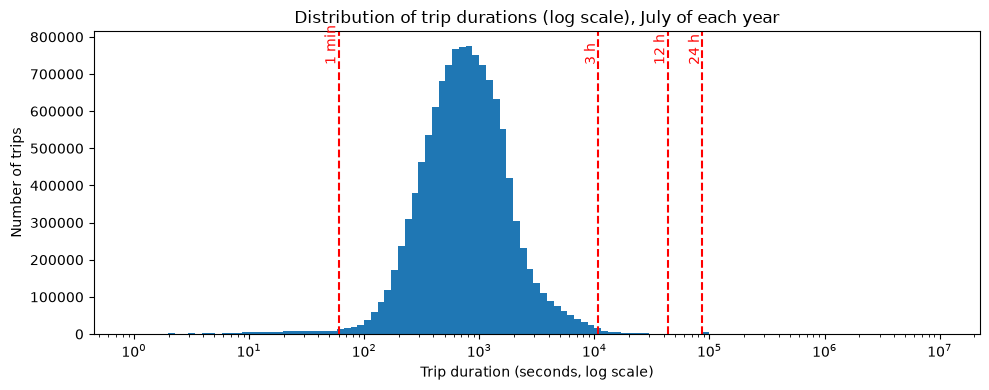

In [16]:
import numpy as np
import matplotlib.pyplot as plt

files = sorted(glob.glob("data/interim/*.parquet"))
july = [f for f in files if "_07__" in f or "07-divvy" in f or "Q3__" in f]
sample = pd.concat(convert_durations(pd.read_parquet(f, columns=["started_at", "ended_at", "duration_s"]))[0]
                   for f in july)
d = sample["duration_s"]

# Share of trips in each "suspicious" zone
print(f"Trips in sample: {len(d):,}")
print(f"<= 0 s (impossible): {(d <= 0).mean()*100:.3f}%")
print(f"< 60 s:              {(d < 60).mean()*100:.3f}%")
for h in [3, 12, 24]:
    print(f"> {h} h:              {(d > h*3600).mean()*100:.3f}%")

# Histogram on a log scale
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(0, 7, 120)                       # from 1 s to 10^7 s (~115 days)
ax.hist(d[d > 0], bins=bins)
ax.set_xscale("log")
for x, label in [(60, "1 min"), (3*3600, "3 h"), (12*3600, "12 h"), (24*3600, "24 h")]:
    ax.axvline(x, color="red", linestyle="--")
    ax.text(x, ax.get_ylim()[1]*0.9, label, color="red", rotation=90, ha="right")
ax.set_title("Distribution of trip durations (log scale), July of each year")
ax.set_xlabel("Trip duration (seconds, log scale)")
ax.set_ylabel("Number of trips")
plt.tight_layout()
plt.show()

#### 📊 Share of trips removed by the duration rules, per day

➕ About 0% before 2020, 1–3% per day after (median 1.00%). Divvy says it removes trips under 60 s, but the new files still contain them: the filter seems no longer applied after 2020. Applying the same rule to all years keeps them comparable. The peaks (up to 13%) are could be days with very few trips, where a few hundred false starts make a large percentage (tested next cell).

Median share removed per day: 1.00%
Days with the highest share removed:
day
2020-03-18    12.89
2020-03-16    11.80
2024-01-16     9.82
2024-01-17     9.79
2020-12-15     8.99
2024-01-15     8.21
2020-03-09     8.01
2024-01-14     8.01
2023-01-26     7.52
2024-01-13     7.49
Name: removed, dtype: float64


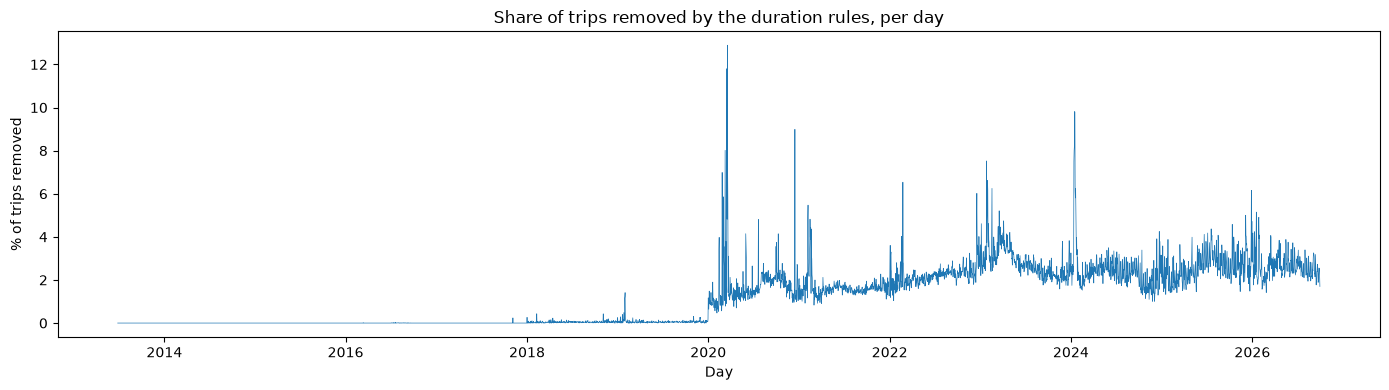

In [17]:
removed_daily = []
for f in sorted(glob.glob("data/interim/*.parquet")):
    df = pd.read_parquet(f, columns=["started_at", "ended_at"])
    dur = (df["ended_at"] - df["started_at"]).dt.total_seconds()
    removed = (dur < 60) | (dur > 24 * 3600)          # includes <= 0 s
    day = df["started_at"].dt.date
    removed_daily.append(pd.DataFrame({"day": day, "removed": removed}))

removed_daily = pd.concat(removed_daily)
share = removed_daily.groupby("day")["removed"].mean() * 100
share.index = pd.to_datetime(share.index)

print(f"Median share removed per day: {share.median():.2f}%")
print("Days with the highest share removed:")
print(share.sort_values(ascending=False).head(10).round(2))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(share.index, share.values, linewidth=0.5)
ax.set_title("Share of trips removed by the duration rules, per day")
ax.set_xlabel("Day")
ax.set_ylabel("% of trips removed")
plt.tight_layout()
plt.show()

#### Detail of the 10 worst days (short vs long trips)

➕ These days have very few trips (587 to 5,225, vs ~24,000–26,000 on a median summer day, and almost all removed trips are false starts. 
- They are unusual days anyway: start of COVID (March 2020), 13–17 January 2024 (probably extreme cold, to confirm with weather data). 
- The cleaning does not create these peaks. January 2024 is a known abnormal period: a test case for the model.

In [18]:
# Recompute with the reason for removal, for the 10 worst days
top_days = share.sort_values(ascending=False).head(10).index.date
rows = []
for f in sorted(glob.glob("data/interim/*.parquet")):
    df = pd.read_parquet(f, columns=["started_at", "ended_at"])
    df = df[df["started_at"].dt.date.isin(top_days)]
    if len(df) == 0:
        continue
    dur = (df["ended_at"] - df["started_at"]).dt.total_seconds()
    rows.append(pd.DataFrame({"day": df["started_at"].dt.date,
                              "short": dur < 60, "long": dur > 24 * 3600}))
detail = pd.concat(rows).groupby("day").agg(
    n_trips=("short", "size"), n_short=("short", "sum"), n_long=("long", "sum"))
detail

,n_trips,n_short,n_long
day,,,
2020-03-09,4505,358,3
2020-03-16,3626,425,3
2020-03-18,2110,270,2
2020-12-15,4784,429,1
2023-01-26,5225,390,3
2024-01-13,1935,139,6
2024-01-14,587,38,9
2024-01-15,731,35,25
2024-01-16,1141,73,39


### Step 5 — Station positions for old trips (2013–2019)
#### The 8 station files

➕ Before 2020, trips only give a station number. The station files list 300 stations (2013) → 585 (end 2017); there is no station file for 2018–2019.

In [22]:
from src.data.stations import load_station_files

stations_raw = load_station_files(inventory)
stations_raw.groupby("source_file")["id"].count()

source_file
Divvy_Stations_2015.csv                                        474
Divvy_Stations_2016_Q3.csv                                     581
Divvy_Stations_2016_Q4.csv                                     581
Divvy_Stations_2017_Q1Q2.csv                                   582
Divvy_Stations_2017_Q3Q4.csv                                   585
Divvy_Stations_Trips_2013/Divvy_Stations_2013.csv              300
Divvy_Stations_Trips_2014_Q3Q4/Divvy_Stations_2014-Q3Q4.csv    300
Divvy_Trips_2016_Q1Q2/Divvy_Stations_2016_Q1Q2.csv             535
Name: id, dtype: int64

#### Stations used in trips but without a position

➕ 633 stations used, 47 without a position: 0% of trips until 2017, 0.73% in 2018, 3.19% in 2019 → stations created after the last station file.

In [23]:
# Stations used in old trips (2013-2019)
old_files = [f for f in glob.glob("data/interim/*.parquet")
             if "Divvy_Trips" in f and "2020" not in f]
trips_old = pd.concat(pd.read_parquet(f, columns=["started_at", "start_station_id"])
                      for f in old_files)
trips_old["start_station_id"] = pd.to_numeric(trips_old["start_station_id"])

# Which stations used in trips are NOT in the station files?
missing = set(trips_old["start_station_id"]) - set(stations_raw["id"])
print("Stations used in trips:", trips_old["start_station_id"].nunique())
print("Stations WITHOUT a position:", len(missing))

# % of trips per year that start at a station without a position
trips_old["no_position"] = trips_old["start_station_id"].isin(missing)
(trips_old.groupby(trips_old["started_at"].dt.year)["no_position"].mean() * 100).round(2)

Stations used in trips: 633
Stations WITHOUT a position: 47


started_at
2013    0.00
2014    0.00
2015    0.00
2016    0.00
2017    0.00
2018    0.73
2019    3.19
Name: no_position, dtype: float64

#### Missing stations found in the 2020 trips

➕ 41 of the 47 found: 2020 trips still use the old numeric IDs and have GPS positions (median position per station).

In [24]:
from src.data.stations import load_station_files, stations_from_2020_trips

stations_2020 = stations_from_2020_trips()
found = stations_2020[stations_2020["id"].isin(missing)]
print("Missing stations found in 2020:", len(found), "out of", len(missing))
found.head(10)

Missing stations found in 2020: 41 out of 47


,id,name,latitude,longitude,n_trips
566,621.0,Aberdeen St & Randolph St,41.884114,-87.654264,5954
572,627.0,LaSalle Dr & Huron St,41.894877,-87.632326,9846
573,628.0,Walsh Park,41.914610,-87.667968,3818
574,630.0,Kildare Ave & Montrose Ave,41.961080,-87.735690,678
575,631.0,Malcolm X College,41.877618,-87.673895,863
576,632.0,Clark St & Newport St,41.944540,-87.654678,10678
577,635.0,Fairbanks St & Superior St,41.895748,-87.620104,6453
578,636.0,Orleans St & Hubbard St,41.890028,-87.636618,5711
579,637.0,Wood St & Chicago Ave,41.895634,-87.672069,3485
580,638.0,Clinton St & Jackson Blvd,41.878116,-87.639838,6281


#### The 6 stations not found

➕ Repair, testing, event and partner stations (249 trips): not real stations, removed in Step 6.

In [25]:
still_missing = missing - set(found["id"])

# Their name and number of trips in 2018-2019
names_old = pd.concat(pd.read_parquet(f, columns=["start_station_id", "start_station_name"])
                      for f in old_files)
names_old["start_station_id"] = pd.to_numeric(names_old["start_station_id"])
(names_old[names_old["start_station_id"].isin(still_missing)]
 .groupby(["start_station_id", "start_station_name"]).size()
 .rename("n_trips").reset_index())

,start_station_id,start_station_name,n_trips
0,1,Special Events,1
1,360,DIVVY Map Frame B/C Station,97
2,361,DIVVY CASSETTE REPAIR MOBILE STATION,144
3,363,TS ~ DIVVY PARTS TESTING,1
4,512,BBB ~ Divvy Parts Testing,5
5,669,LBS - BBB La Magie,1


#### Name check: 2018–2019 vs 2020

➕ 29 of 41 names identical; the other 12 only differ by the marker "(*)" → same stations.

In [26]:
old_names = (names_old[names_old["start_station_id"].isin(found["id"])]
             .groupby("start_station_id")["start_station_name"]
             .agg(lambda s: s.mode().iloc[0]).rename("name_2018_2019"))
check = found.set_index("id").join(old_names)
check["same_name"] = check["name"] == check["name_2018_2019"]
print("Same name:", check["same_name"].sum(), "out of", len(check))
check.loc[~check["same_name"], ["name_2018_2019", "name"]]

Same name: 29 out of 41


,name_2018_2019,name
id,,
627.0,LaSalle Dr & Huron St (*),LaSalle Dr & Huron St
635.0,Fairbanks St & Superior St (*),Fairbanks St & Superior St
636.0,Orleans St & Hubbard St (*),Orleans St & Hubbard St
637.0,Wood St & Chicago Ave (*),Wood St & Chicago Ave
643.0,Smith Park (*),Smith Park
644.0,Western Ave & Fillmore St (*),Western Ave & Fillmore St
649.0,Stewart Ave & 63rd St (*),Stewart Ave & 63rd St
650.0,Eggleston Ave & 69th St (*),Eggleston Ave & 69th St
654.0,Racine Ave & Washington Blvd (*),Racine Ave & Washington Blvd


#### Position check: official position vs 2020 median position (571 stations)

➕ Median distance 0.0 m, 96% within 100 m, maximum 792 m → the 2020 method recovers the true positions.

In [27]:
# Official position: the latest station file for each station
official = stations_raw.drop_duplicates("id", keep="last").set_index("id")
compare = official.join(stations_2020.set_index("id"), rsuffix="_2020", how="inner")

# Distance in metres between the two positions (haversine formula)
lat1, lon1 = np.radians(compare["latitude"]), np.radians(compare["longitude"])
lat2, lon2 = np.radians(compare["latitude_2020"]), np.radians(compare["longitude_2020"])
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
compare["distance_m"] = 6_371_000 * 2 * np.arcsin(np.sqrt(a))

print("Stations compared:", len(compare))
print(compare["distance_m"].describe().round(1))
print("Share within 100 m:", round((compare["distance_m"] < 100).mean() * 100, 1), "%")

Stations compared: 571
count    571.0
mean      11.0
std       50.9
min        0.0
25%        0.0
50%        0.0
75%        0.1
max      792.4
Name: distance_m, dtype: float64
Share within 100 m: 96.0 %


#### Final station table

➕ 627 stations (586 official + 41 from the 2020 trips), saved in `data/stations.csv`.

In [28]:
from src.data.stations import build_station_table

stations = build_station_table(stations_raw, stations_2020, missing)
stations.to_csv("data/stations.csv", index=False)
print(len(stations), "stations")
stations["source"].value_counts()

627 stations


source
station_file    586
2020_trips       41
Name: count, dtype: int64

#### 📊 Map of the stations 2013–2019, by source of position

➕ All stations inside Chicago; the 41 filled from 2020 are mostly at the edges of the network, where it was expanding in 2018–2019.

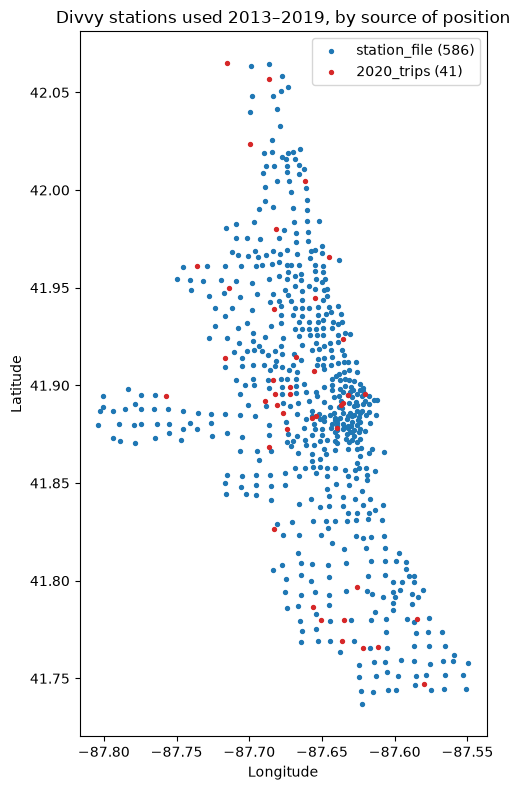

In [29]:
fig, ax = plt.subplots(figsize=(6, 8))
for source, color in [("station_file", "tab:blue"), ("2020_trips", "tab:red")]:
    s = stations[stations["source"] == source]
    ax.scatter(s["longitude"], s["latitude"], s=8, c=color,
               label=f"{source} ({len(s)})")
ax.set_title("Divvy stations used 2013–2019, by source of position")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(41.88)))   # correct proportions at Chicago's latitude
ax.legend()
plt.tight_layout()
plt.show()

### Step 6 — Cleaning rules
#### Search for technical stations (keywords)

➕ Station names containing TEST, REPAIR, WAREHOUSE… saved in `data/interim/suspicious_stations.csv`, then checked by hand → 21 technical stations (list in `src/data/clean.py`).



In [30]:
import re

pattern = r"TEST|REPAIR|WAREHOUSE|WH\b|CHECKING|BASE|HUB|MOBILE|SPECIAL|LBS|DIVVY|MAP FRAME"
counts = {}
for f in sorted(glob.glob("data/interim/*.parquet")):
    names = pd.read_parquet(f, columns=["start_station_name"])["start_station_name"].dropna()
    hits = names[names.str.contains(pattern, case=False, regex=True)]
    for name, n in hits.value_counts().items():
        counts[name] = counts.get(name, 0) + n

suspicious = pd.Series(counts, name="n_trips").sort_values(ascending=False)
pd.set_option("display.max_rows", 100)
suspicious

suspicious.to_csv("data/interim/suspicious_stations.csv")

#### Test of the rules on two files (2019 Q2, July 2023)

➕ 5 rules, in order: R1 duration · R2 technical station · R3 no start position · R4 outside Chicago · R5 duplicate trip ID. Example July 2023: 767,650 → 746,412 trips (R1 21,227, R2 11).

In [31]:
from src.data.clean import add_values, apply_rules

stations = pd.read_csv("data/stations.csv")
for pattern in ["data/interim/Divvy_Trips_2019_Q2__*.parquet",
                "data/interim/202307-divvy-tripdata__*.parquet"]:
    df = pd.read_parquet(glob.glob(pattern)[0])
    df = add_values(df, stations)
    clean, log = apply_rules(df)
    print(pattern.split("/")[-1], log)
    display(clean.head(3))

Divvy_Trips_2019_Q2__*.parquet {'rows_before': 1108163, 'R1_duration': 462, 'R2_technical_station': 67, 'R3_no_start_position': 0, 'R4_outside_chicago': 0, 'R5_duplicate_trip_id': 0, 'rows_after': 1107634, 'unknown_user_type': 0}


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip,has_station
0,22178529,2019-04-01 00:02:22,2019-04-01 00:09:48,446.0,81,Daley Center Plaza,56,Desplaines St & Kinzie St,41.884241,-87.629634,41.888716,-87.644448,member,classic,Divvy_Trips_2019_Q2.zip,True
1,22178530,2019-04-01 00:03:02,2019-04-01 00:20:30,1048.0,317,Wood St & Taylor St,59,Wabash Ave & Roosevelt Rd,41.869154,-87.671045,41.867227,-87.625961,member,classic,Divvy_Trips_2019_Q2.zip,True
2,22178531,2019-04-01 00:11:07,2019-04-01 00:15:19,252.0,283,LaSalle St & Jackson Blvd,174,Canal St & Madison St,41.878170,-87.631985,41.882091,-87.639833,member,classic,Divvy_Trips_2019_Q2.zip,True


202307-divvy-tripdata__*.parquet {'rows_before': 767650, 'R1_duration': 21227, 'R2_technical_station': 11, 'R3_no_start_position': 0, 'R4_outside_chicago': 0, 'R5_duplicate_trip_id': 0, 'rows_after': 746412, 'unknown_user_type': 0}


,trip_id,started_at,ended_at,duration_s,start_station_id,start_station_name,end_station_id,end_station_name,start_lat,start_lng,end_lat,end_lng,user_type,bike_type,source_zip,has_station
0,9340B064F0AEE130,2023-07-23 20:06:14,2023-07-23 20:22:44,990.0,20204,Kedzie Ave & 110th St,877,Public Rack - Racine Ave & 109th Pl,41.692406,-87.700905,41.694835,-87.653041,member,electric,202307-divvy-tripdata.zip,True
1,D1460EE3CE0D8AF8,2023-07-23 17:05:07,2023-07-23 17:18:37,810.0,KA1504000103,Western Ave & Walton St,13033,Milwaukee Ave & Grand Ave,41.898418,-87.686596,41.891578,-87.648384,member,classic,202307-divvy-tripdata.zip,True
2,DF41BE31B895A25E,2023-07-23 10:14:53,2023-07-23 10:24:29,576.0,KA1504000103,Western Ave & Walton St,TA1305000041,Damen Ave & Pierce Ave,41.898418,-87.686596,41.909396,-87.677692,member,classic,202307-divvy-tripdata.zip,True


### Step 7 — Full cleaning run
#### Cleaning of all files → `data/clean/`

➕ Result: 58,209,830 → 57,339,571 trips (1.50% removed): R1 duration 865,638 · R2 technical stations 4,559 · R3 no position 0 · R4 outside Chicago 1 · R5 duplicates in a file 61. 
- Unknown rider types after cleaning: 0. The next cells check the result; 
- the last cells removes the duplicates between files (always run it after this cell).

In [32]:
from src.data.pipeline import run_steps_4_to_7

stations = pd.read_csv("data/stations.csv")
cleaning_log, daily_cleaning = run_steps_4_to_7(stations)
cleaning_log.to_csv("data/clean/cleaning_log.csv", index=False)
daily_cleaning.to_csv("data/clean/daily_cleaning.csv")

totals = cleaning_log.drop(columns="file").sum()
print(totals)
print(f"\nRemoved in total: {(1 - totals['rows_after'] / totals['rows_before']) * 100:.2f}%")

1/108 202004-divvy-tripdata__202004-divvy-tripdata.parquet: 84,776 -> 83,627
2/108 202005-divvy-tripdata__202005-divvy-tripdata.parquet: 200,274 -> 197,612
3/108 202006-divvy-tripdata__202006-divvy-tripdata.parquet: 343,005 -> 338,187
4/108 202007-divvy-tripdata__202007-divvy-tripdata.parquet: 551,480 -> 542,596
5/108 202008-divvy-tripdata__202008-divvy-tripdata.parquet: 622,361 -> 608,891
6/108 202009-divvy-tripdata__202009-divvy-tripdata.parquet: 532,958 -> 521,941
7/108 202010-divvy-tripdata__202010-divvy-tripdata.parquet: 388,653 -> 379,653
8/108 202011-divvy-tripdata__202011-divvy-tripdata.parquet: 259,716 -> 255,029
9/108 202012-divvy-tripdata__202012-divvy-tripdata.parquet: 131,573 -> 129,428
10/108 202101-divvy-tripdata__202101-divvy-tripdata.parquet: 96,834 -> 95,350
11/108 202102-divvy-tripdata__202102-divvy-tripdata.parquet: 49,622 -> 48,526
12/108 202103-divvy-tripdata__202103-divvy-tripdata.parquet: 228,496 -> 225,352
13/108 202104-divvy-tripdata__202104-divvy-tripdata.par

#### Check: unknown rider types

➕ In the raw files, 190 trips (2015–2017) have the rider type "Dependent" (maybe person linked to a member's account ???). They are converted to "member" in the cleaning (`clean.py`).

In [33]:
from src.data.harmonize import load_harmonized  # not needed, we read interim directly
odd = []
for f in sorted(glob.glob("data/interim/*__*.parquet")):
    ut = pd.read_parquet(f, columns=["user_type"])["user_type"]
    bad = ut[~ut.isin(["Subscriber", "Customer", "member", "casual"])]
    if len(bad):
        odd.append(bad.value_counts(dropna=False).rename(f.split("/")[-1]))
pd.concat(odd, axis=1).fillna(0).astype(int).T

user_type,Dependent
Divvy_Trips_2015-Q1__Divvy_Trips_2015-Q1Q2.parquet,24
Divvy_Trips_2015-Q2__Divvy_Trips_2015-Q1Q2.parquet,27
Divvy_Trips_2015_07__Divvy_Trips_2015_Q3Q4.parquet,17
Divvy_Trips_2015_08__Divvy_Trips_2015_Q3Q4.parquet,28
Divvy_Trips_2015_09__Divvy_Trips_2015_Q3Q4.parquet,24
Divvy_Trips_2015_Q4__Divvy_Trips_2015_Q3Q4.parquet,23
Divvy_Trips_2016_Q3__Divvy_Trips_2016_Q3Q4.parquet,26
Divvy_Trips_2016_Q4__Divvy_Trips_2016_Q3Q4.parquet,14
Divvy_Trips_2017_Q1__Divvy_Trips_2017_Q1Q2.parquet,4
Divvy_Trips_2017_Q3__Divvy_Trips_2017_Q3Q4.parquet,3


#### Duplicates inside files (R5)

➕ 61 trips were written twice in the same file (2016 Q1, 2016 Q3, 2017 Q2): already removed by the cleaning (rule R5).

In [34]:
cleaning_log[cleaning_log["R5_duplicate_trip_id"] > 0][["file", "R5_duplicate_trip_id"]]

,file,R5_duplicate_trip_id
92,Divvy_Trips_2016_Q1__Divvy_Trips_2016_Q1Q2.par...,1
93,Divvy_Trips_2016_Q3__Divvy_Trips_2016_Q3Q4.par...,49
96,Divvy_Trips_2017_Q2__Divvy_Trips_2017_Q1Q2.par...,11


#### Duplicates between files

➕ Rule R5 only works inside one file, so we compare each file with the next one: only 2 pairs share trips, May → June 2024 (168) and April → May 2026 (28). Explained in the next two cells, removed in the last one.

In [35]:
# Sort the clean files by their first trip date
files = sorted(glob.glob("data/clean/*__*.parquet"))
first_date = {f: pd.read_parquet(f, columns=["started_at"])["started_at"].min() for f in files}
files = sorted(files, key=first_date.get)

overlaps = []
for f1, f2 in zip(files[:-1], files[1:]):
    ids1 = set(pd.read_parquet(f1, columns=["trip_id"])["trip_id"])
    ids2 = pd.read_parquet(f2, columns=["trip_id"])["trip_id"]
    n_common = ids2.isin(ids1).sum()
    if n_common:
        overlaps.append({"file_1": f1.split("/")[-1], "file_2": f2.split("/")[-1],
                         "common_trip_ids": n_common})
print("Pairs of files sharing trips:", len(overlaps))
pd.DataFrame(overlaps)

Pairs of files sharing trips: 2


,file_1,file_2,common_trip_ids
0,202405-divvy-tripdata__202405-divvy-tripdata.p...,202406-divvy-tripdata__202406-divvy-tripdata.p...,168
1,202604-divvy-tripdata__202604-divvy-tripdata.p...,202605-divvy-tripdata__202605-divvy-tripdata.p...,28


#### When did the May–June 2024 duplicates start?

➕ All on 31 May 2024, mostly in the last hour (median 23:46): trips crossing midnight. From June 2024 Divvy files trips by the month they end in.

In [36]:
may = set(pd.read_parquet(glob.glob("data/clean/202405-divvy*")[0], columns=["trip_id"])["trip_id"])
june = pd.read_parquet(glob.glob("data/clean/202406-divvy*")[0], columns=["trip_id", "started_at"])
june[june["trip_id"].isin(may)]["started_at"].describe()

count                           168
mean     2024-05-31 23:10:16.266910
min      2024-05-31 11:49:34.737000
25%      2024-05-31 23:21:43.897750
50%      2024-05-31 23:46:40.926500
75%      2024-05-31 23:54:22.771500
max      2024-05-31 23:59:57.389000
Name: started_at, dtype: object

#### Trips crossing midnight on 31 March 2026

➕ 0 in both files (vs 19 crossing midnight on 28 February): about 20 trips are missing that night (change of export method back to the start date). Negligible.

In [37]:
march = pd.read_parquet(glob.glob("data/clean/202603-divvy*")[0], columns=["started_at", "ended_at"])
april = pd.read_parquet(glob.glob("data/clean/202604-divvy*")[0], columns=["started_at", "ended_at"])

# Trips crossing midnight on 31 March -> 1 April, in each file
cross_march = march[(march["started_at"] < "2026-04-01") & (march["ended_at"] >= "2026-04-01")]
cross_april = april[(april["started_at"] < "2026-04-01") & (april["ended_at"] >= "2026-04-01")]
print("In the March file:", len(cross_march))
print("In the April file:", len(cross_april))

# For comparison: trips crossing midnight on 28 Feb -> 1 March (normal transition)
feb = pd.read_parquet(glob.glob("data/clean/202603-divvy*")[0], columns=["started_at", "ended_at"])
print("Feb->March crossings found in the March file:",
      ((feb["started_at"] < "2026-03-01") & (feb["ended_at"] >= "2026-03-01")).sum())

In the March file: 0
In the April file: 0
Feb->March crossings found in the March file: 19


#### Removal of the duplicates between files

➕ 196 trips removed from the later file → **57,339,375 clean trips**.

In [38]:
from src.data.pipeline import remove_cross_file_duplicates

removed_cross = remove_cross_file_duplicates()
print(removed_cross)

{'202406-divvy-tripdata__202406-divvy-tripdata.parquet': 168, '202605-divvy-tripdata__202605-divvy-tripdata.parquet': 28}


#### 📊 Share of trips removed by each rule, per year

➕ About 0% until 2017, ~0.05% in 2018–2019, 1.6–2.8% per year from 2020, almost entirely R1 (false starts under 60 s).

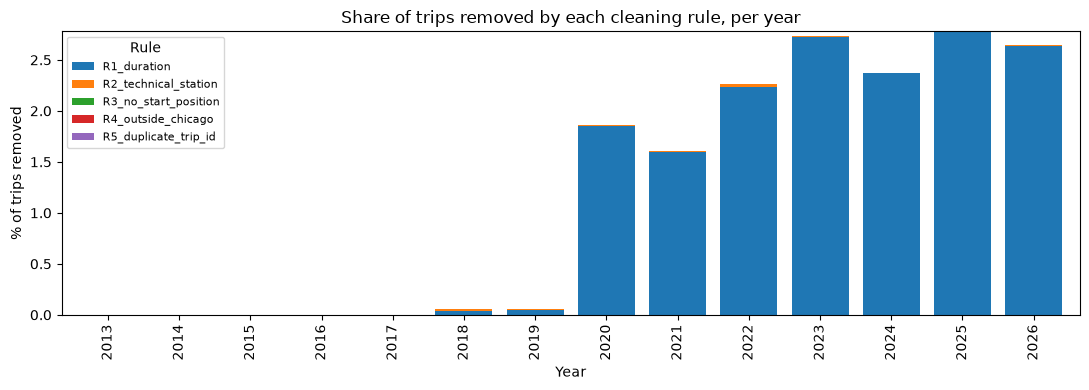

,R1_duration,R2_technical_station,R3_no_start_position,R4_outside_chicago,R5_duplicate_trip_id
year,,,,,
2013,0.000,0.000,0.0,0.0,0.000
2014,0.000,0.000,0.0,0.0,0.000
2015,0.000,0.000,0.0,0.0,0.000
2016,0.000,0.000,0.0,0.0,0.001
2017,0.000,0.000,0.0,0.0,0.000
2018,0.042,0.013,0.0,0.0,0.000
2019,0.048,0.005,0.0,0.0,0.000
2020,1.849,0.009,0.0,0.0,0.000
2021,1.595,0.013,0.0,0.0,0.000


In [40]:
log = pd.read_csv("data/clean/cleaning_log.csv")
first = {f.split("/")[-1]: pd.read_parquet(f, columns=["started_at"])["started_at"].min().year
         for f in glob.glob("data/clean/*__*.parquet")}
log["year"] = log["file"].map(first)

rules = ["R1_duration", "R2_technical_station", "R3_no_start_position",
         "R4_outside_chicago", "R5_duplicate_trip_id"]
per_year = log.groupby("year")[["rows_before"] + rules].sum()
pct = per_year[rules].div(per_year["rows_before"], axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4))
pct.plot(kind="bar", stacked=True, ax=ax, width=0.8)
ax.set_title("Share of trips removed by each cleaning rule, per year")
ax.set_xlabel("Year")
ax.set_ylabel("% of trips removed")
ax.legend(title="Rule", fontsize=8)
plt.tight_layout()
plt.show()

pct.round(3)

#### 📊 Share of trips removed per day, all rules (second version of the Step 4 plot, now with all rules)

➕ Median 1.01% per day; same peaks as with the duration rules only: the other rules create no peaks.

➕ **Conclusion of the cleaning:** 57.3 million trips kept (98.5%). Every removed trip is explained or negligible, the share removed per day is low and stable, and all years are cleaned the same way: the cleaning creates no fake anomalies.

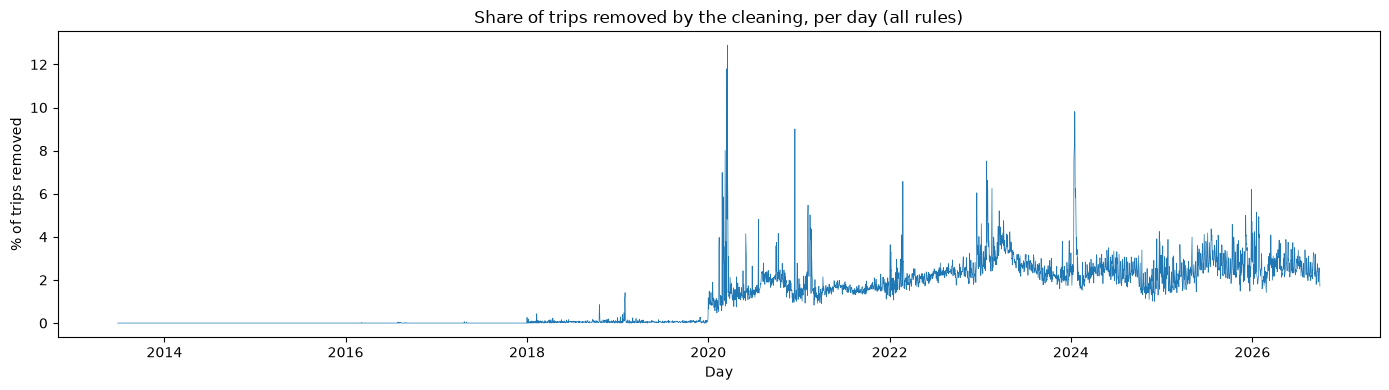

Median per day: 1.01 %
            before   after  pct_removed
started_at                             
2020-03-18    2110  1838.0    12.890995
2020-03-16    3626  3198.0    11.803640
2024-01-16    1141  1029.0     9.815951
2024-01-17    2932  2645.0     9.788540
2020-12-15    4784  4353.0     9.009197


In [41]:
daily = pd.read_csv("data/clean/daily_cleaning.csv", index_col=0, parse_dates=True).sort_index()
daily["pct_removed"] = (1 - daily["after"] / daily["before"]) * 100

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily["pct_removed"], linewidth=0.5)
ax.set_title("Share of trips removed by the cleaning, per day (all rules)")
ax.set_xlabel("Day")
ax.set_ylabel("% of trips removed")
plt.tight_layout()
plt.show()

print("Median per day:", round(daily["pct_removed"].median(), 2), "%")
print(daily.sort_values("pct_removed", ascending=False).head(5))

#### Summary of the clean data

➕ 57,339,375 clean trips, 16 columns (dates as datetimes, positions as numbers). 
- Columns and types of the clean files, and per year: number of trips, share of casual riders, of e-bikes and of trips without a station.

In [42]:
rows = []
for f in sorted(glob.glob("data/clean/*__*.parquet")):
    d = pd.read_parquet(f, columns=["started_at", "user_type", "bike_type", "start_station_name"])
    d["year"] = d["started_at"].dt.year
    d["casual"] = d["user_type"] == "casual"
    d["electric"] = d["bike_type"] == "electric"
    d["no_station"] = d["start_station_name"].isna()
    rows.append(d.groupby("year")[["casual", "electric", "no_station"]].agg(["sum", "size"]))
by_year = pd.concat(rows).groupby(level=0).sum()

summary = pd.DataFrame({"trips": by_year[("casual", "size")]})
for col in ["casual", "electric", "no_station"]:
    summary[f"% {col}"] = (100 * by_year[(col, "sum")] / summary["trips"]).round(1)
print(f"Total: {summary['trips'].sum():,} clean trips\n")
print(pd.read_parquet(f).dtypes, "\n")      # columns and types of the clean files
summary

Total: 57,339,375 clean trips

trip_id                          str
started_at            datetime64[us]
ended_at              datetime64[us]
duration_s                   Float64
start_station_id                 str
start_station_name               str
end_station_id                   str
end_station_name                 str
start_lat                    float64
start_lng                    float64
end_lat                      float64
end_lng                      float64
user_type                        str
bike_type                        str
source_zip                       str
has_station                     bool
dtype: object 



,trips,% casual,% electric,% no_station
year,,,,
2013,759788,47.0,0.0,0.0
2014,2454634,32.2,0.0,0.0
2015,3183439,29.2,0.0,0.0
2016,3595333,23.9,0.0,0.0
2017,3829003,21.9,0.0,0.0
2018,3601116,18.8,0.0,0.0
2019,3815979,23.0,0.0,0.0
2020,3475872,38.6,14.2,2.6
2021,5505068,45.3,36.1,12.2


#### Station IDs change format over time

➕ Results : Until 2019, IDs are numbers (300 → ~610 stations). From 2020, numbers are mixed with codes (`KA1504000140`, `TA1306000002`), and from 2025 a new format appears (`CHI01924`); in 2026 only `CHI…` codes remain. In 2025, 3,297 distinct IDs: the same stations appear under two formats.

- A station cannot be followed over time by its ID, because the ID format changes.
- We work with positions (zones), so this is not a problem for us.
- If we later zoom in on an anomaly station by station, we will use station names and positions, not IDs : if the case we will need to check if the stations name stay theh same. 

In [43]:
parts = []
for f in sorted(glob.glob("data/clean/*__*.parquet")):
    d = pd.read_parquet(f, columns=["started_at", "start_station_id"]).dropna()
    parts.append(pd.DataFrame({"year": d["started_at"].dt.year, "id": d["start_station_id"]}).drop_duplicates())
ids = pd.concat(parts).drop_duplicates()
ids["numeric"] = ids["id"].str.fullmatch(r"\d+(\.0)?")
id_formats = ids.groupby("year").agg(
    distinct_ids=("id", "size"),
    pct_numeric=("numeric", lambda s: round(100 * s.mean(), 1)),
    examples=("id", lambda s: ", ".join(s.sample(min(3, len(s)), random_state=0))))
id_formats

,distinct_ids,pct_numeric,examples
year,,,
2013,300,100.0,"237, 201, 61"
2014,300,100.0,"106, 286, 74"
2015,475,100.0,"62, 225, 441"
2016,581,100.0,"535, 510, 209"
2017,585,100.0,"243, 603, 101"
2018,617,100.0,"374, 588, 27"
2019,611,100.0,"580, 239, 407"
2020,1228,75.7,"198, 591, 20"
2021,831,63.9,"KA1504000140, TA1306000002, 13164"


## 2. Descriptive statistics (to add)

➕ sections found in `jeanne.ipynb`: 0 base tables · 1 is 2022–2025 a stable period? · 2 choice of the grid · 3 stations. Only the final plots will be copied here, calling the functions from `src/`.

## 3. Choice of the grid  (to add)

➕ sections found in `jeanne.ipynb`:

## 4. External data (to add)

## 5. Model a "normal" day


#### 📊 Trips per day, whole city (2022–2025)

➕ Two humps: winter days around 4,000–9,000 trips, summer days around 22,000–26,000 (range ~500–35,000). An average day means nothing on its own: the model must first explain the season and the weekday.

Days: 1461 | mean 15,211 | median 14,930 | std 8,505 | min 261 | max 35,280


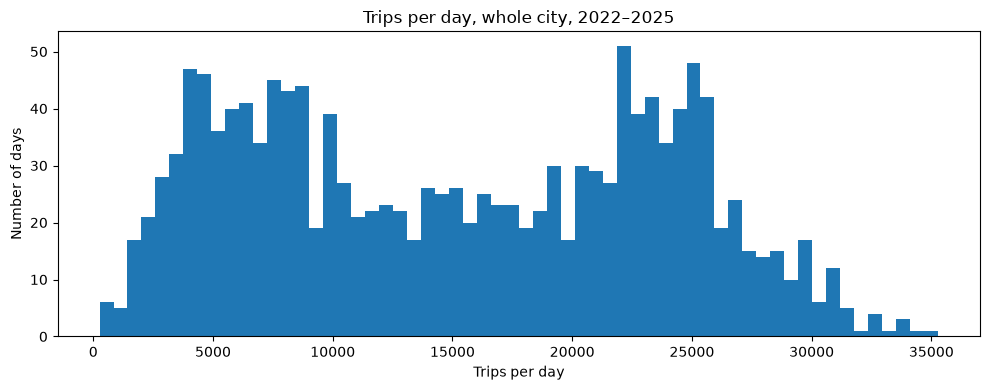

In [46]:
hourly = pd.read_parquet("data/hourly_counts.parquet")
city_day = hourly.groupby(hourly["hour"].dt.normalize())["n_trips"].sum()
city_day = city_day[(city_day.index.year >= 2022) & (city_day.index.year <= 2025)]

print(f"Days: {len(city_day)} | mean {city_day.mean():,.0f} | median {city_day.median():,.0f} "
      f"| std {city_day.std():,.0f} | min {city_day.min():,} | max {city_day.max():,}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(city_day, bins=60)
ax.set_title("Trips per day, whole city, 2022–2025")
ax.set_xlabel("Trips per day")
ax.set_ylabel("Number of days")
plt.tight_layout()
plt.show()

#### 📊 Variance vs mean of similar days (per zone, 2022–2025)

➕ Quiet zones follow the Poisson line (variance = mean), but for busier zones the variance grows like mean², far above Poisson: the counts are overdispersed. 
➕ The negative binomial (variance = mean + α·mean², α ≈ 0.084) fits the points well. 

A Poisson model would flag many fake anomalies, so we could use a negative binomial. Part of this variance (weather, holidays) will be explained by the model.

Groups of similar days: 7,246 | variance > mean in 86% | estimated alpha (median): 0.084


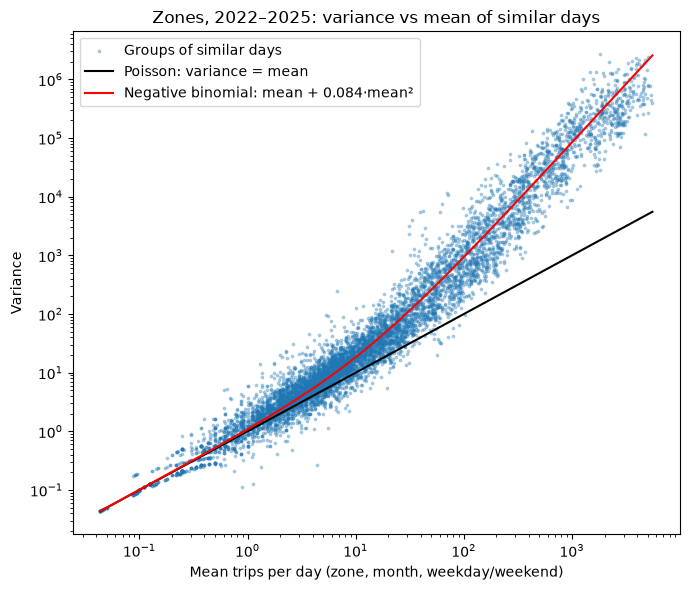

In [47]:
zh = pd.read_parquet("data/zone_hourly_counts.parquet")
zh = zh[(zh["zone_id"] > 0) & zh["hour"].dt.year.between(2022, 2025)]
zh["date"] = zh["hour"].dt.normalize()
zd = zh.groupby(["date", "zone_id"])["n_trips"].sum()

# add the zone-days with 0 trips
all_dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
zd = zd.reindex(pd.MultiIndex.from_product([all_dates, range(1, 78)], names=["date", "zone_id"]),
                fill_value=0).reset_index()
zd["month"] = zd["date"].dt.to_period("M")
zd["weekend"] = zd["date"].dt.dayofweek >= 5

g = zd.groupby(["zone_id", "month", "weekend"])["n_trips"].agg(["mean", "var"])
g = g[g["mean"] > 0]
alpha = ((g["var"] - g["mean"]) / g["mean"] ** 2).median()
print(f"Groups of similar days: {len(g):,} | variance > mean in {100 * (g['var'] > g['mean']).mean():.0f}% "
      f"| estimated alpha (median): {alpha:.3f}")

m = np.logspace(np.log10(g["mean"].min()), np.log10(g["mean"].max()), 100)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(g["mean"], g["var"], s=3, alpha=0.3, label="Groups of similar days")
ax.plot(m, m, color="black", label="Poisson: variance = mean")
ax.plot(m, m + alpha * m ** 2, color="red", label=f"Negative binomial: mean + {alpha:.3f}·mean²")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean trips per day (zone, month, weekday/weekend)")
ax.set_ylabel("Variance")
ax.set_title("Zones, 2022–2025: variance vs mean of similar days")
ax.legend()
plt.tight_layout()
plt.show()